# 03 — DEM (Copernicus GLO-30) e perfis
> **Estudo educacional independente; não substitui o PAE oficial, a Defesa Civil ou laudo de engenharia.**

DEM: Copernicus GLO-30, ~30 m, **MDS** (inclui vegetação/edificações), datum horizontal WGS84, **vertical EGM2008**. Precisão vertical nominal < 4 m (90%). **Perfis são descritivos: não se infere alcance de inundação por comparação de cotas.**

In [1]:
import sys, warnings; warnings.filterwarnings('ignore')
sys.path.insert(0, '../src')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
from jurumirim import DISCLAIMER
print(DISCLAIMER)

Estudo educacional independente; não substitui o PAE oficial, a Defesa Civil ou laudo de engenharia.


In [2]:
from jurumirim import data
from jurumirim.terrain import section_geometries, profile, DEM_PATH
from jurumirim.georef import fit_transform
import rasterio
with rasterio.open(DEM_PATH) as s: print(s.crs, s.res, s.shape, s.nodata)
A,_ = fit_transform(); sec = data.sections(); geoms = section_geometries(A, sec)

EPSG:4326 (0.0002777777777777778, 0.0002777777777777778) (1260, 1440) None


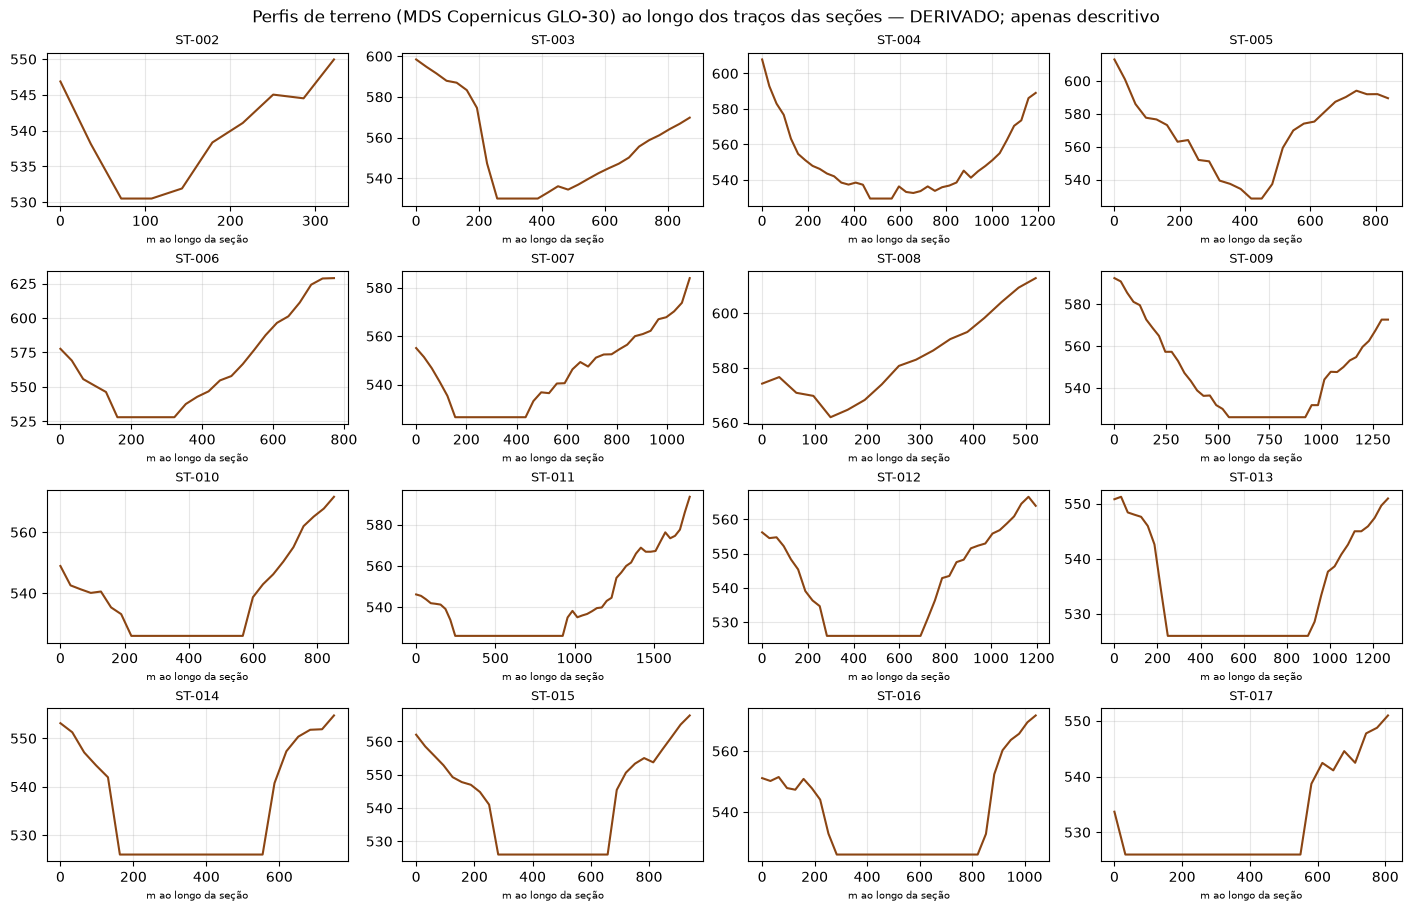

In [3]:
fig, axes = plt.subplots(4, 4, figsize=(14, 9), sharey=False, constrained_layout=True)
for ax, (sid, g) in zip(axes.ravel(), [(k,v) for k,v in geoms.items() if v is not None]):
    p = profile(g); ax.plot(p.dist_m, p.z_m, color='saddlebrown'); ax.set_title(sid, fontsize=9)
    ax.set_xlabel('m ao longo da seção', fontsize=7); ax.grid(alpha=.3)
fig.suptitle('Perfis de terreno (MDS Copernicus GLO-30) ao longo dos traços das seções — DERIVADO; apenas descritivo'); plt.show()

## Sensibilidade à resolução do DEM
Agregamos o DEM (fator 3, ~90 m) e comparamos as cotas amostradas nas seções.

In [4]:
from rasterio.enums import Resampling
from jurumirim.terrain import sample_dem
import numpy as np, rasterio
from pyproj import Transformer
t = Transformer.from_crs(31982, 4326, always_xy=True)
lon, lat = t.transform(sec.x_utm.values, sec.y_utm.values)
with rasterio.open(DEM_PATH) as src:
    z30 = np.array([v[0] for v in src.sample(zip(lon, lat))], float)
    arr = src.read(1, out_shape=(src.height//3, src.width//3), resampling=Resampling.average)
    tr = src.transform * src.transform.scale(3, 3)
    z90 = np.array([arr[rasterio.transform.rowcol(tr, x, y)] for x, y in zip(lon, lat)], float)
d = pd.DataFrame({'id': sec.id, 'z30': z30, 'z90': z90, 'dif': z90 - z30}); print(d.round(1).to_string()); print('|dif| médio:', d.dif.abs().mean().round(2), 'm; máx:', d.dif.abs().max().round(2), 'm')

        id    z30    z90  dif
0   ST-001  564.0  564.0 -0.0
1   ST-002  531.9  538.3  6.4
2   ST-003  536.1  532.5 -3.6
3   ST-004  536.3  531.9 -4.4
4   ST-005  528.5  532.5  4.0
5   ST-006  542.8  548.6  5.8
6   ST-007  526.5  527.2  0.7
7   ST-008  576.6  575.8 -0.9
8   ST-009  526.0  526.0  0.0
9   ST-010  526.0  526.0  0.0
10  ST-011  526.0  526.0  0.0
11  ST-012  526.0  526.0  0.0
12  ST-013  526.0  526.0  0.0
13  ST-014  526.0  526.0  0.0
14  ST-015  526.0  526.0  0.0
15  ST-016  526.0  526.0  0.0
16  ST-017  526.0  526.0  0.0
|dif| médio: 1.52 m; máx: 6.41 m


A diferença de poucos metros entre resoluções é comparável à incerteza vertical do DEM — mais um motivo para **não** usar cotas do DEM para refinar a mancha.